# Satellite Scheduling — Visibility Windows → CSP → Dimensionality Reduction

Full pipeline from wrangled data to a problem whose complexity has been reduced using CSP.

In [1]:
import sys, os, copy, time, random
sys.path.insert(0, os.path.join('..', 'src'))

import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path
from collections import Counter

from CSP import CSP, CSP_Variable, Timeslot, ac3, split_connected_components

import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

random.seed(42)

## 1. Load the Scheduling Instance

In [2]:
# Switch between small / medium / dense for different problem scales
TARGET_DATASET = "starlink_scheduling_slots_weighted.csv"
DATA_PATH = Path('../data/dataset/starlink/') / TARGET_DATASET

df = pd.read_csv(DATA_PATH)
disc_step_s = int(df['discretization_step_seconds'].iloc[0])
disc_step_h = disc_step_s / 3600

print("-"*10 + " dataset sumamry info " + "-"*10)
print(f'Dataset        : {TARGET_DATASET}')
print(f'Num. candidate slots : {len(df):,}')
print(f'Num. satellites      : {df["satellite_name"].nunique()}')
print(f'Num. antennas        : {df["antenna_id"].nunique()}')
print(f'Num. parent windows  : {df["parent_window_id"].nunique()}')
print(f'Num. disc. step      : {disc_step_s}s  ({disc_step_h:.4f}h)')
print(f'Tot. time horizon    : {df["start_time_hours"].min():.3f} - {df["start_time_hours"].max():.3f}h')

df[['slot_id', 'satellite_name', 'antenna_id', 'parent_window_id',
    'start_time_hours', 'end_time_hours', 'candidate_index_in_parent',
    'priority', 'urgency', 'weight']].head(5)

---------- dataset sumamry info ----------
Dataset        : starlink_scheduling_slots_weighted.csv
Num. candidate slots : 563
Num. satellites      : 29
Num. antennas        : 39
Num. parent windows  : 441
Num. disc. step      : 120s  (0.0333h)
Tot. time horizon    : 0.000 - 3.917h


,slot_id,satellite_name,antenna_id,parent_window_id,start_time_hours,end_time_hours,candidate_index_in_parent,priority,urgency,weight
0,SLOT_000001,STARLINK-1039,ANT_GATEWAY_0005,VIS_000001,0.000000,0.083333,1,3,5,70.340
1,SLOT_000002,STARLINK-1012,ANT_GATEWAY_0015,VIS_000002,0.016667,0.100000,1,2,5,52.822
2,SLOT_000003,STARLINK-1039,ANT_GATEWAY_0005,VIS_000001,0.033333,0.116667,2,3,5,70.340
3,SLOT_000004,STARLINK-1008,ANT_GATEWAY_0015,VIS_000004,0.033333,0.116667,1,3,5,64.082
4,SLOT_000005,STARLINK-1036,ANT_GATEWAY_0015,VIS_000005,0.033333,0.116667,1,5,5,83.144


## 2. Time-Discrete Reference System

Each raw *visibility window* says that *Satellite **S** can communicate with antenna **A** between **T₁** and **T₂**.*

**Discretisation** slides a fixed-length contact window of `min_contact_duration` over \[T₁, T₂\] in steps of `disc_step_s`, generating one *candidate slot* per valid placement. Each parent window therefore yields 1–N alternatives, all with the same priority/urgency inherited from the parent.

The plot below shows the parent windows (shaded bars) and the candidate slots (ticks) on the time axis.

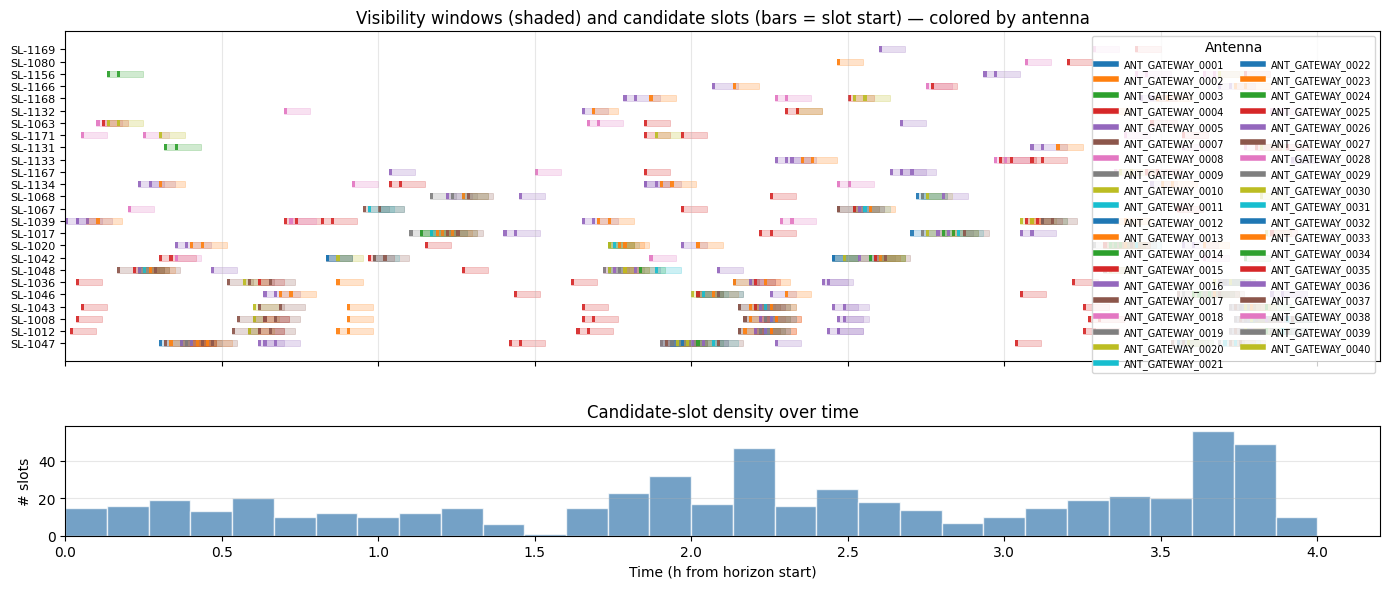

Slots per window: avg=1.28, max=2, min=1


In [3]:
# -------------------------------------------------------
# Show the satellites' vibility windows in the sky
# -------------------------------------------------------

# extract the start/end time of the original visibility window (and its serving antenna)
window_bounds = (
    df.groupby(['satellite_name', 'parent_window_id'])
    .agg(win_start=('start_time_hours', 'min'),
         win_end=('end_time_hours', 'max'),
         antenna_id=('antenna_id', 'first'))
    .reset_index()
)

# get the original visibility windows of the first
SAT_TO_DISPLAY = 25
top_sats = (
    df.groupby('satellite_name')['parent_window_id']
    .nunique().sort_values(ascending=False).head(SAT_TO_DISPLAY).index.tolist()
)

antennas = sorted(df['antenna_id'].unique())
cmap = plt.colormaps['tab10']
ant_color = {a: cmap(i % 10) for i, a in enumerate(antennas)}

fig, axes = plt.subplots(2, 1, figsize=(14, 6),
                         gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

# --- upper: satellite visibility timeline, colored by serving antenna ---
ax = axes[0]
for i, sat in enumerate(top_sats):
    sat_wins  = window_bounds[window_bounds['satellite_name'] == sat]
    sat_slots = df[df['satellite_name'] == sat]

    # drow the original visibility window
    for _, row in sat_wins.iterrows():
        color = ant_color[row['antenna_id']]
        ax.barh(i, row['win_end'] - row['win_start'], left=row['win_start'],
                height=0.5, color=color, alpha=0.22, edgecolor=color, linewidth=0.7)

    # draw the discretized timeslot: a thin bar marking just the start of each slot
    for _, row in sat_slots.iterrows():
        color = ant_color[row['antenna_id']]
        ax.barh(i, disc_step_h * 0.3, left=row['start_time_hours'], height=0.5,
                color=color, alpha=0.9, edgecolor='none')

ax.set_yticks(range(len(top_sats)))
ax.set_yticklabels([s.replace('STARLINK-', 'SL-') for s in top_sats], fontsize=8)
ax.set_title('Visibility windows (shaded) and candidate slots (bars = slot start) — colored by antenna')
ax.grid(axis='x', alpha=0.3)
legend_handles = [plt.Line2D([0], [0], color=ant_color[a], lw=4, label=a) for a in antennas]
ax.legend(handles=legend_handles, loc='upper right', fontsize=7, ncol=2, title='Antenna')

# --- bottom: slot density over time ---
ax2 = axes[1]
bins = np.arange(0, df['start_time_hours'].max() + disc_step_h * 4, disc_step_h * 4)
ax2.hist(df['start_time_hours'], bins=bins, color='steelblue', alpha=0.75, edgecolor='white')
ax2.set_xlabel('Time (h from horizon start)')
ax2.set_ylabel('# slots')
ax2.set_title('Candidate-slot density over time')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

spc = df.groupby('parent_window_id').size()
print(f'Slots per window: avg={spc.mean():.2f}, max={spc.max()}, min={spc.min()}')

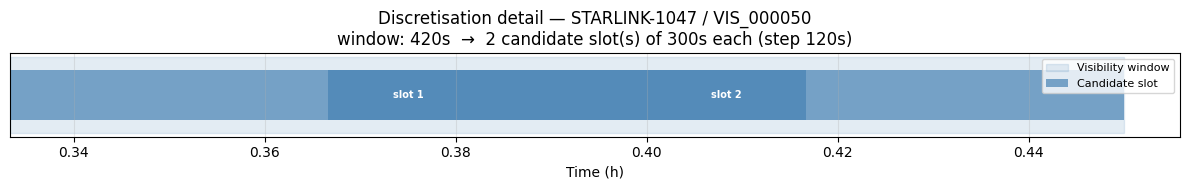

In [4]:
# -------------------------------------------------------
# Example of vibility window
# -------------------------------------------------------

# pick up some satellite as example
example_sat = df.groupby('satellite_name').size().idxmax()
ex = df[df['satellite_name'] == example_sat].sort_values('start_time_hours')
example_win = ex.groupby('parent_window_id').size().idxmax()
ex_win = ex[ex['parent_window_id'] == example_win]

win_s = ex_win['start_time_hours'].min()
win_e = ex_win['end_time_hours'].max()
slot_dur_s = int(ex_win['duration_seconds'].iloc[0])
slot_dur_h = slot_dur_s / 3600

# draw the original window
fig, ax = plt.subplots(figsize=(12, 2))
ax.barh(0, win_e - win_s, left=win_s, height=0.6, color='steelblue',
        alpha=0.15, edgecolor='steelblue', label='Visibility window')

# draw the derived candidate slots
for k, t_h in enumerate(ex_win['start_time_hours']):
    ax.barh(0, slot_dur_h, left=t_h, height=0.4,
            color='steelblue', alpha=0.7,
            label='Candidate slot' if k == 0 else '')
    ax.text(t_h + slot_dur_h / 2, 0, f'slot {k+1}',
            ha='center', va='center', fontsize=7, color='white', fontweight='bold')

ax.set_yticks([])
ax.set_xlabel('Time (h)')
ax.set_title(
    f'Discretisation detail — {example_sat} / {example_win}\n'
    f'window: {(win_e-win_s)*3600:.0f}s  →  {len(ex_win)} candidate slot(s) of {slot_dur_s}s each (step {disc_step_s}s)'
)
ax.legend(loc='upper right', fontsize=8)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Translating to CSP

| Entity | CSP element |
|---|---|
| Satellite *S* | `CSP_Variable` (one per unique satellite) |
| Candidate slot at antenna *A*, starting at time *T* | `Timeslot(antenna_id=int(A), timeframe=round(T / disc_step_h))` |
| All candidate slots of satellite *S* | Domain of variable *S* |
| Two satellites share a `Timeslot` | *Constraint* (Diff formulation: they cannot both be assigned it) |

In [5]:
# TODO: shape this part passing by the model class

satellites = sorted(df['satellite_name'].unique())
antennas   = sorted(df['antenna_id'].unique())
# look-up dictionary to index variables
sat_to_id  = {s: i for i, s in enumerate(satellites)}
ant_to_id  = {a: i for i, a in enumerate(antennas)}

# to convert continous the staring time in some kind of discrete index
def to_timeframe(start_h: float) -> int:
    return round(start_h / disc_step_h)

# build the CSP
csp = CSP(max_vars=len(satellites))

for sat_name in satellites:
    sat_rows = df[df['satellite_name'] == sat_name]
    sat_weight = df[df["satellite_name"] == sat_name]["weight"].iloc[0]
    var = CSP_Variable(id=sat_to_id[sat_name], name=sat_name, weight=sat_weight)
    for _, row in sat_rows.iterrows():
        var.add_value(Timeslot(
            antenna_id=ant_to_id[row['antenna_id']],
            timeframe=to_timeframe(row['start_time_hours']),
        ))
    csp.add_var(var)


# --- prettier summary print ---
def print_summary(label, summ):
    print(f'\n{"-"*46}')
    print(f'  {label}')
    print(f'{"-"*46}')
    for k, v in summ.items():
        val = f'{v:.4f}' if isinstance(v, float) else str(int(v))
        print(f'  {k:<24} {val}')

summary_before = csp.compute_summary()
print_summary('CSP  —  BEFORE preprocessing', summary_before)

# Save a copy for comparison after dimensionality reduction
csp_before = copy.deepcopy(csp)


----------------------------------------------
  CSP  —  BEFORE preprocessing
----------------------------------------------
  num_vars                 29
  avg_domain_size          18.6552
  sd_domain_size           15.7026
  min_domain_size          1.0000
  max_domain_size          63.0000
  num_const                19
  avg_degree               1.3103
  sd_degree                1.0538
  const_dens               0.0468


### Problem Structure Before Preprocessing

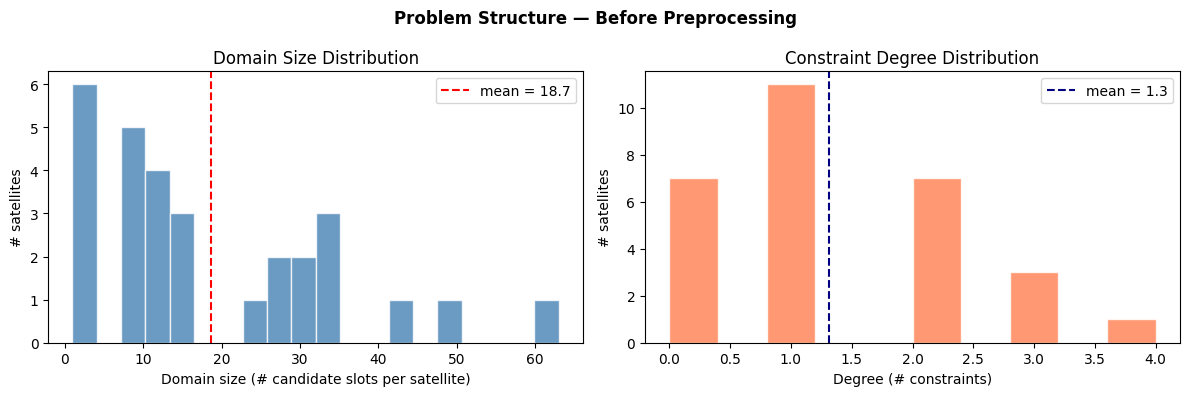

In [6]:
# just some barplots if the CSP elements distributions

domain_sizes = [len(v.domain) for v in csp.vars]
degrees      = [csp.degree(v) for v in csp.vars]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(domain_sizes, bins=max(10, len(set(domain_sizes))),
             color='steelblue', alpha=0.8, edgecolor='white')
axes[0].axvline(np.mean(domain_sizes), color='red', linestyle='--',
                label=f'mean = {np.mean(domain_sizes):.1f}')
axes[0].set_xlabel('Domain size (# candidate slots per satellite)')
axes[0].set_ylabel('# satellites')
axes[0].set_title('Domain Size Distribution')
axes[0].legend()

axes[1].hist(degrees, bins=max(10, len(set(degrees))),
             color='coral', alpha=0.8, edgecolor='white')
axes[1].axvline(np.mean(degrees), color='navy', linestyle='--',
                label=f'mean = {np.mean(degrees):.1f}')
axes[1].set_xlabel('Degree (# constraints)')
axes[1].set_ylabel('# satellites')
axes[1].set_title('Constraint Degree Distribution')
axes[1].legend()

plt.suptitle('Problem Structure — Before Preprocessing', fontweight='bold')
plt.tight_layout()
plt.show()

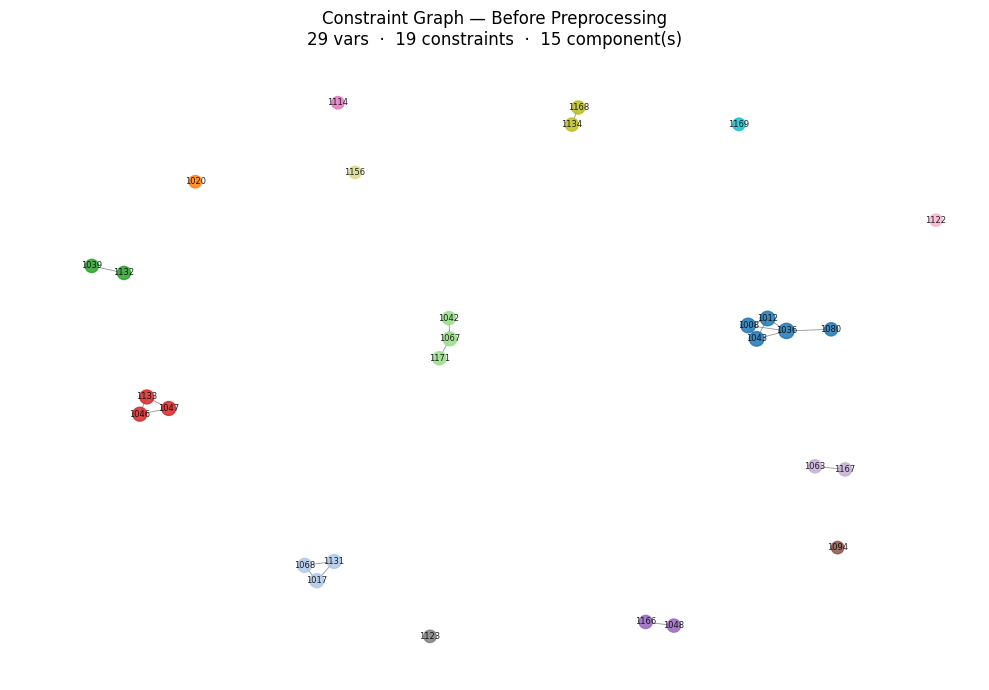

In [7]:
# using networkx draw the problem's graph

def draw_csp_graph(csp: CSP, title: str, ax, max_nodes: int=-1, seed: int=42):
    vars_sample = (
        csp.vars if max_nodes < 0
        else random.sample(csp.vars, max_nodes)
    )
    G = nx.Graph()
    G.add_nodes_from(v.id for v in vars_sample)
    for v in vars_sample:
        for u in vars_sample:
            if u.id > v.id and csp.constraint_exists(v, u):
                G.add_edge(v.id, u.id)

    comps = list(nx.connected_components(G))
    cmap  = plt.colormaps['tab20']
    node_color = {n: cmap(ci / max(len(comps), 1))
                  for ci, comp in enumerate(comps)
                  for n in comp}

    labels = {v.id: v.name.replace('STARLINK-', '') for v in vars_sample}
    pos = nx.spring_layout(G, seed=seed)
    nx.draw_networkx(
        G, pos, ax=ax,
        node_color=[node_color[n] for n in G.nodes()],
        node_size=[80 + 10 * G.degree(n) for n in G.nodes()],
        labels=labels, font_size=6,
        edge_color='gray', alpha=0.85, width=0.6,
    )
    n_comp = len(comps)
    ax.set_title(
        f'{title}\n'
        f'{G.number_of_nodes()} vars  ·  {G.number_of_edges()} constraints  ·  {n_comp} component(s)'
    )
    ax.axis('off')

fig, ax = plt.subplots(figsize=(10, 7))
draw_csp_graph(csp, 'Constraint Graph — Before Preprocessing', ax)
plt.tight_layout()
plt.show()

## 4. Dimensionality Reduction
The **Diff formulation** add a constraint between two satellites if their domains share a `Timeslot`. 

The problem's complexity decomposition is composed by two phases:

### AC-3 Arc Consistency

AC-3 iteratively:
1. Removes unsupported values from domains
2. Prunes constraints between variables whose domains have become disjoint
3. Propagates changes to neighbours

Returns `False` if any domain is wiped out (infeasible problem).

### Connected-Component Decomposition

After AC-3, variables with no remaining shared slots are completely independent. Splitting the CSP into connected components allows each sub-problem to be sent separately to the quantum annealer — dramatically reducing the QUBO size per call.

In [8]:
t0 = time.time()
feasible = ac3(csp)
elapsed_ms = (time.time() - t0) * 1000

if not feasible: print('AC-3: problem turned out to be unfeasible')
else:
    print(f'AC-3 completed in {elapsed_ms:.1f} ms')

summary_after_ac3 = csp.compute_summary()
print_summary('CSP  —  AFTER AC-3', summary_after_ac3)

# Show variables prune
pruned = [
    (v.name, len(csp_before._var_by_id[v.id].domain), len(v.domain))
    for v in csp.vars
    if len(v.domain) < len(csp_before._var_by_id[v.id].domain)
]
print(f'\nSatellites with pruned domains : {len(pruned)}')
print(f'Constraints removed by AC-3   : {int(summary_before["num_const"] - summary_after_ac3["num_const"])}')
if pruned:
    print('\nPruned variables (name, before, after):')
    for name, b, a in pruned:
        print(f'  {name:<20}  {b} -> {a}  (-{b-a})')

AC-3 completed in 7.1 ms

----------------------------------------------
  CSP  —  AFTER AC-3
----------------------------------------------
  num_vars                 29
  avg_domain_size          18.6552
  sd_domain_size           15.7026
  min_domain_size          1.0000
  max_domain_size          63.0000
  num_const                19
  avg_degree               1.3103
  sd_degree                1.0538
  const_dens               0.0468

Satellites with pruned domains : 0
Constraints removed by AC-3   : 0


In [9]:
con_components = split_connected_components(csp)
sizes = sorted([len(c.vars) for c in con_components], reverse=True)
component_constraints = [c.num_constraints() for c in con_components]
# QUBO size = number of (variable, timeslot) binary variables in the sub-problem
# qubo_sizes = [sum(len(v.domain) for v in c.vars) for c in components]

print(f'Connected components after AC-3 : {len(con_components)}')
print(f'  Sizes (# satellites)  : {sizes}')
print(f'  Largest component     : {sizes[0]} satellites')
print(f'  Singleton components  : {sum(1 for s in sizes if s == 1)}')
#print(f'  QUBO sizes per comp.  : {sorted(qubo_sizes, reverse=True)}')
#print(f'  Largest QUBO          : {max(qubo_sizes)} binary variables')
#print(f'  Original QUBO size    : {sum(len(v.domain) for v in csp_before.vars)} binary variables')

Connected components after AC-3 : 15
  Sizes (# satellites)  : [5, 3, 3, 3, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1]
  Largest component     : 5 satellites
  Singleton components  : 7


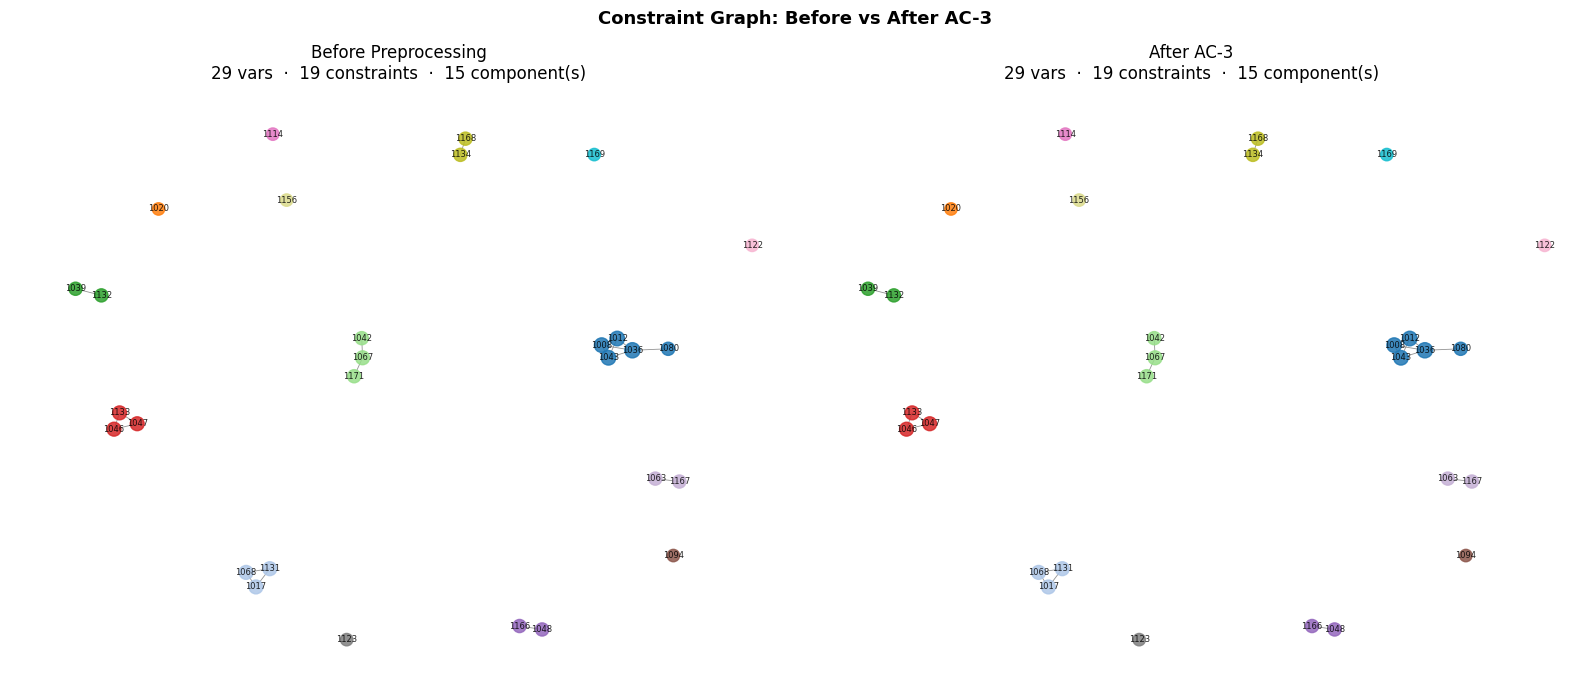

In [10]:
# Side-by-side constraint graphs
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
draw_csp_graph(csp_before, 'Before Preprocessing', axes[0], seed=42)
draw_csp_graph(csp,        'After AC-3',           axes[1], seed=42)
plt.suptitle('Constraint Graph: Before vs After AC-3', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

"\naxes[1].bar(range(len(sorted(qubo_sizes, reverse=True))),\n            sorted(qubo_sizes, reverse=True),\n            color='mediumpurple', alpha=0.85, edgecolor='white')\naxes[1].set_xlabel('Component index (sorted by QUBO size)')\naxes[1].set_ylabel('# binary QUBO variables')\naxes[1].set_title('QUBO Size per Component (= sum of domain sizes)')\naxes[1].axhline(sum(len(v.domain) for v in csp_before.vars) / len(components) if components else 0,\n                color='red', linestyle='--', label='avg if not split')\naxes[1].legend(fontsize=8)\n\nplt.suptitle('After AC-3 + Connected-Component Decomposition', fontweight='bold')\nplt.tight_layout()\nplt.show()\n"

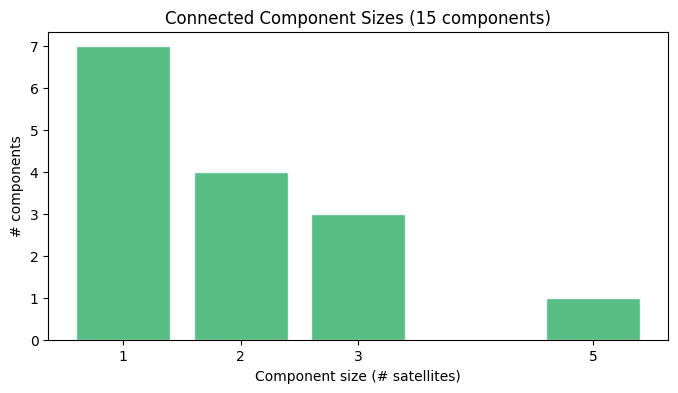

In [11]:
# Component-size distribution
fig, axes = plt.subplots(1, 1, figsize=(8, 4))

size_counts = Counter(sizes)
bars = sorted(size_counts.keys())
axes.bar(bars, [size_counts[b] for b in bars],
            color='mediumseagreen', alpha=0.85, edgecolor='white')
axes.set_xlabel('Component size (# satellites)')
axes.set_ylabel('# components')
axes.set_title(f'Connected Component Sizes ({len(con_components)} components)')
if max(bars) <= 20:
    axes.set_xticks(bars)
"""
axes[1].bar(range(len(sorted(qubo_sizes, reverse=True))),
            sorted(qubo_sizes, reverse=True),
            color='mediumpurple', alpha=0.85, edgecolor='white')
axes[1].set_xlabel('Component index (sorted by QUBO size)')
axes[1].set_ylabel('# binary QUBO variables')
axes[1].set_title('QUBO Size per Component (= sum of domain sizes)')
axes[1].axhline(sum(len(v.domain) for v in csp_before.vars) / len(components) if components else 0,
                color='red', linestyle='--', label='avg if not split')
axes[1].legend(fontsize=8)

plt.suptitle('After AC-3 + Connected-Component Decomposition', fontweight='bold')
plt.tight_layout()
plt.show()
"""

## 5. CSP → QUBO Translation

Each `(satellite, candidate slot)` pair becomes one binary QUBO variable `x[v, t]` (see `src/CSP_to_QUBO.py`). The QUBO energy combines three terms:

| Term | Effect |
|---|---|
| Reward (`-assignment_gain` on the diagonal) | Encourages picking *some* slot for each satellite |
| One-hot penalty | Penalizes a satellite picking more than one slot from its own domain |
| Conflict penalty | Penalizes two satellites picking the same shared slot |

Since `con_components` are mutually independent (no constraint crosses a component boundary), each one is translated into its **own** QUBO and solved separately — this is the whole point of the decomposition: smaller, independent problems instead of one large one.

In [12]:
from CSP_to_QUBO import csp_to_qubo, decode_sample
import neal

# slove the issue taking advantage of problem decomposition
component_qubos = [(comp, *csp_to_qubo(comp)) for comp in con_components]

total_qubo_vars = sum(len(index_map) for _, _, index_map in component_qubos)
total_qubo_terms = sum(len(q) for _, q, _ in component_qubos)
largest_qubo_vars = max((len(index_map) for _, _, index_map in component_qubos), default=0)

print(f'Connected components (sub-problems) : {len(component_qubos)}')
print(f'Total QUBO binary variables         : {total_qubo_vars:,}')
print(f'Total QUBO terms (Q entries)        : {total_qubo_terms:,}')
print(f'Largest sub-problem QUBO variables  : {largest_qubo_vars:,}')

Connected components (sub-problems) : 15
Total QUBO binary variables         : 541
Total QUBO terms (Q entries)        : 9,006
Largest sub-problem QUBO variables  : 156


The QUBO instance is solved here with `dwave-neal`'s `SimulatedAnnealingSampler` — a classical, D-Wave-API-compatible annealer (therefore just a simulation, not an actual quantum annealing).

In [13]:
sampler = neal.SimulatedAnnealingSampler()

# Solve each component's QUBO independently and merge the decoded assignments
assignment = {}
component_results = []
t0 = time.time()
for comp, q, index_map in component_qubos:
    response = sampler.sample_qubo(q, num_reads=200, num_sweeps=1000, seed=42)
    assignment.update(decode_sample(response.first.sample, comp, index_map))
    component_results.append({
        'size': len(comp.vars),
        'qubo_vars': len(index_map),
        'energy': response.first.energy,
        'num_reads': len(response),
    })
elapsed_ms = (time.time() - t0) * 1000

total_energy = sum(r['energy'] for r in component_results)
total_reads = sum(r['num_reads'] for r in component_results)
assigned  = sum(1 for t in assignment.values() if t is not None)
conflicts = sum(
    1
    for v in csp.vars
    for u in csp.neighbors(v)
    if u.id > v.id
    and assignment.get(v.id) is not None
    and assignment.get(v.id) == assignment.get(u.id)
)

print(f'Annealing time (all components) : {elapsed_ms:.1f} ms  ({len(component_qubos)} sub-problems, {total_reads} total reads)')
print(f'Total QUBO energy (sum of best) : {total_energy:.2f}')
print(f'Satellites scheduled            : {assigned} / {len(csp.vars)}')
print(f'Constraint violations           : {conflicts}')

Annealing time (all components) : 6619.6 ms  (15 sub-problems, 3000 total reads)
Total QUBO energy (sum of best) : -125.54
Satellites scheduled            : 29 / 29
Constraint violations           : 0


In [14]:
# resulting schedule
schedule_rows = []
for v in sorted(csp.vars, key=lambda v: v.id):
    t = assignment.get(v.id)
    schedule_rows.append({
        'satellite': v.name,
        'antenna_id': t.antenna_id if t else None,
        'timeframe': t.timeframe if t else None,
        'scheduled': t is not None,
    })
schedule_df = pd.DataFrame(schedule_rows)
schedule_df

,satellite,antenna_id,timeframe,scheduled
0,STARLINK-1008,31,68,True
1,STARLINK-1012,9,112,True
2,STARLINK-1017,38,82,True
3,STARLINK-1020,21,100,True
4,STARLINK-1036,38,112,True
5,STARLINK-1039,35,94,True
6,STARLINK-1042,38,26,True
7,STARLINK-1043,24,112,True
8,STARLINK-1046,14,116,True
9,STARLINK-1047,37,58,True


## 6. Classical algorithm for comparison
The QUBO rewards each satellite independently of *which* Timeslot it gets, and only
enforces: (1) at most one Timeslot per satellite (one-hot), (2) at most one satellite
per shared Timeslot (conflict). That is exactly a **maximum-weight matching** between
satellites and Timeslots — solvable to global optimality in polynomial time with classic
graph algorithms, no annealing required.

This gives an exact ground truth to measure the optimality gap of the QUBO/simulated-annealing
pipeline above.


In [15]:
import networkx as nx


def solve_max_weight_matching(csp):
    """
    Solve the CSP to global optimality via maximum-weight matching.

    Bipartite graph: satellites tagged ("var", id) on one side, distinct
    Timeslots tagged ("slot", Timeslot) on the other, with an edge per
    (satellite, Timeslot) in that satellite's domain weighted by the
    satellite's weight. A maximum-weight matching picks at most one
    Timeslot per satellite and at most one satellite per Timeslot — the
    one-hot and conflict constraints — while maximizing total scheduled
    weight: the exact optimum the QUBO above only approximates.
    """
    graph = nx.Graph()
    for v in csp.vars:
        var_node = ("var", v.id)
        for t in v.domain:
            graph.add_edge(var_node, ("slot", t), weight=v.weight)

    matching = nx.max_weight_matching(graph, maxcardinality=False)

    result = {v.id: None for v in csp.vars}
    for a, b in matching:
        var_node, slot_node = (a, b) if a[0] == "var" else (b, a)
        result[var_node[1]] = slot_node[1]
    return result


def evaluate_assignment(csp, assignment):
    """Scheduled count / total weight / conflicts for any {var_id: Timeslot|None} assignment."""
    scheduled = [v for v in csp.vars if assignment.get(v.id) is not None]
    conflicts = sum(
        1
        for v in csp.vars
        for u in csp.neighbors(v)
        if u.id > v.id
        and assignment.get(v.id) is not None
        and assignment.get(v.id) == assignment.get(u.id)
    )
    return {
        "num_scheduled": len(scheduled),
        "total_weight": sum(v.weight for v in scheduled),
        "num_conflicts": conflicts,
    }


In [16]:
# Solve the matching baseline per component too, then aggregate the stats
baseline_assignment = {}
baseline_elapsed_ms = 0.0
baseline_stats = {"num_scheduled": 0, "total_weight": 0.0, "num_conflicts": 0}
sa_stats = {"num_scheduled": 0, "total_weight": 0.0, "num_conflicts": 0}

for comp in con_components:
    t0 = time.time()
    comp_baseline = solve_max_weight_matching(comp)
    baseline_elapsed_ms += (time.time() - t0) * 1000
    baseline_assignment.update(comp_baseline)

    comp_sa_assignment = {v.id: assignment.get(v.id) for v in comp.vars}

    for stats, comp_assign in ((baseline_stats, comp_baseline), (sa_stats, comp_sa_assignment)):
        comp_eval = evaluate_assignment(comp, comp_assign)
        stats["num_scheduled"] += comp_eval["num_scheduled"]
        stats["total_weight"] += comp_eval["total_weight"]
        stats["num_conflicts"] += comp_eval["num_conflicts"]

comparison_df = pd.DataFrame([
    {"method": "Max-weight matching (exact)", "runtime_ms": baseline_elapsed_ms, **baseline_stats},
    {"method": "QUBO + simulated annealing",  "runtime_ms": elapsed_ms,          **sa_stats},
])
comparison_df["optimality_gap_%"] = (
    100 * (1 - comparison_df["total_weight"] / baseline_stats["total_weight"])
)
comparison_df


,method,runtime_ms,num_scheduled,total_weight,num_conflicts,optimality_gap_%
0,Max-weight matching (exact),35.48789,29,1705.844,0,0.0
1,QUBO + simulated annealing,6619.56048,29,1705.844,0,0.0


### Solution comparison

In [17]:
agreements = [
    v for v in csp.vars
    if baseline_assignment.get(v.id) == assignment.get(v.id)
]
mismatches_rows = [
    {
        "satellite": v.name,
        "baseline_slot": baseline_assignment.get(v.id),
        "sa_slot": assignment.get(v.id),
    }
    for v in csp.vars
    if baseline_assignment.get(v.id) != assignment.get(v.id)
]

print(f'Satellites agreeing on assignment : {len(agreements)} / {len(csp.vars)}'
      f'  ({100 * len(agreements) / len(csp.vars):.1f}%)')
print(f'Satellites disagreeing            : {len(mismatches_rows)}')

mismatches_df = pd.DataFrame(mismatches_rows)
mismatches_df


Satellites agreeing on assignment : 7 / 29  (24.1%)
Satellites disagreeing            : 22


,satellite,baseline_slot,sa_slot
0,STARLINK-1008,"Timeslot(antenna_id=34, timeframe=68)","Timeslot(antenna_id=31, timeframe=68)"
1,STARLINK-1012,"Timeslot(antenna_id=3, timeframe=68)","Timeslot(antenna_id=9, timeframe=112)"
2,STARLINK-1017,"Timeslot(antenna_id=19, timeframe=37)","Timeslot(antenna_id=38, timeframe=82)"
3,STARLINK-1020,"Timeslot(antenna_id=17, timeframe=98)","Timeslot(antenna_id=21, timeframe=100)"
4,STARLINK-1036,"Timeslot(antenna_id=24, timeframe=111)","Timeslot(antenna_id=38, timeframe=112)"
5,STARLINK-1039,"Timeslot(antenna_id=13, timeframe=24)","Timeslot(antenna_id=35, timeframe=94)"
6,STARLINK-1042,"Timeslot(antenna_id=34, timeframe=76)","Timeslot(antenna_id=38, timeframe=26)"
7,STARLINK-1043,"Timeslot(antenna_id=0, timeframe=112)","Timeslot(antenna_id=24, timeframe=112)"
8,STARLINK-1046,"Timeslot(antenna_id=4, timeframe=116)","Timeslot(antenna_id=14, timeframe=116)"
9,STARLINK-1047,"Timeslot(antenna_id=35, timeframe=62)","Timeslot(antenna_id=37, timeframe=58)"


In [18]:
def assignment_to_sample(assignment, index_map):
    """Encode a {var_id: Timeslot|None} assignment as a binary QUBO sample."""
    return {
        idx: int(assignment.get(var_id) == t)
        for (var_id, t), idx in index_map.items()
    }


def qubo_energy(Q, sample):
    """Evaluate the QUBO objective sum_{i<=j} Q[i,j] * x_i * x_j for a binary sample."""
    energy = 0.0
    for (i, j), coeff in Q.items():
        energy += coeff * sample.get(i, 0) if i == j else coeff * sample.get(i, 0) * sample.get(j, 0)
    return energy


# Cross-check energies per component, then sum, instead of against one global QUBO
baseline_energy = 0.0
sa_energy = 0.0
for comp, q, index_map in component_qubos:
    baseline_energy += qubo_energy(q, assignment_to_sample(baseline_assignment, index_map))
    sa_energy += qubo_energy(q, assignment_to_sample(assignment, index_map))

print(f'QUBO energy — max-weight matching (true optimum) : {baseline_energy:.2f}')
print(f'QUBO energy — simulated annealing (best read)     : {sa_energy:.2f}')
print(f'Difference (SA - baseline)                         : {sa_energy - baseline_energy:+.2f}')


QUBO energy — max-weight matching (true optimum) : -125.54
QUBO energy — simulated annealing (best read)     : -125.54
Difference (SA - baseline)                         : +0.00
